# EDA · Univariado y variable objetivo

**Tarea de Jira:** DSAP-7 · **Responsable:** Laura · **Dataset:** NYC 311 (`nyc_311_safety.parquet`)

**Objetivo:** Describir cada variable por separado, entender la variable objetivo candidata y su desbalance.

In [10]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Conexion con la API

Los datos provienen de la API oficial NYC Open Data (311 Service Requests from 2020 to Present). Se utiliza el período 2022–2025 y se agrupan las solicitudes por día, borough y tipo de queja.

In [11]:
URL_API = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

respuesta = requests.get(
    URL_API,
    params={"$limit": 1},
    timeout=30
)

respuesta.raise_for_status()

print("Conexión exitosa con NYC Open Data")

Conexión exitosa con NYC Open Data


## 2. Obtencion de datos para analisis

In [12]:
registros = []
limite = 10000

for anio in range(2022, 2026):
    offset = 0

    while True:
        params = {
            "$select": (
                "borough, "
                "date_trunc_ymd(created_date) as dia, "
                "complaint_type, "
                "count(*) as n"
            ),
            "$where": (
                f"created_date >= '{anio}-01-01T00:00:00' "
                f"AND created_date < '{anio + 1}-01-01T00:00:00'"
            ),
            "$group": (
                "borough, "
                "date_trunc_ymd(created_date), "
                "complaint_type"
            ),
            "$order": "dia, borough, complaint_type",
            "$limit": limite,
            "$offset": offset
        }

        respuesta = requests.get(
            URL_API,
            params=params,
            timeout=180
        )
        respuesta.raise_for_status()

        lote = respuesta.json()
        registros.extend(lote)

        if len(lote) < limite:
            break

        offset += limite

    print(f"Año {anio} descargado")

df = pd.DataFrame(registros)

df["dia"] = pd.to_datetime(df["dia"])
df["n"] = pd.to_numeric(df["n"])

print("Dimensiones:", df.shape)
display(df.head())

Año 2022 descargado
Año 2023 descargado
Año 2024 descargado
Año 2025 descargado
Dimensiones: (652635, 4)


,borough,dia,complaint_type,n
0,BRONX,2022-01-01,Abandoned Vehicle,3
1,BRONX,2022-01-01,Animal-Abuse,2
2,BRONX,2022-01-01,Animal in a Park,1
3,BRONX,2022-01-01,APPLIANCE,5
4,BRONX,2022-01-01,Bike/Roller/Skate Chronic,1


## 3. Análisis univariado de la demanda semanal

Se analiza la distribución del número de solicitudes semanales por borough, con el propósito de identificar su variabilidad y establecer una base para construir la variable objetivo `nivel_demanda`.

In [15]:
# Conservar únicamente los cinco boroughs de Nueva York
df_eda = df[df["borough"].isin([
    "BRONX",
    "BROOKLYN",
    "MANHATTAN",
    "QUEENS",
    "STATEN ISLAND"
])].copy()

print("Dimensiones:", df_eda.shape)
print("Total de solicitudes:", df_eda["n"].sum())

Dimensiones: (644285, 4)
Total de solicitudes: 13491431


In [16]:
# Agrupar solicitudes por semana y borough
df_semanal = df_eda.copy()

df_semanal["semana"] = (
    df_semanal["dia"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

demanda_semanal = (
    df_semanal
    .groupby(["borough", "semana"], as_index=False)["n"]
    .sum()
    .rename(columns={"n": "total_solicitudes"})
)

display(demanda_semanal.head())

print("Dimensiones:", demanda_semanal.shape)

,borough,semana,total_solicitudes
0,BRONX,2021-12-27,2256
1,BRONX,2022-01-03,12056
2,BRONX,2022-01-10,16275
3,BRONX,2022-01-17,14508
4,BRONX,2022-01-24,14915


Dimensiones: (1050, 3)


Conservar semanas completas dentro de 2022–2025

In [ ]:

inicio = pd.Timestamp("2022-01-03")
fin = pd.Timestamp("2025-12-22")

demanda_semanal = demanda_semanal[
    demanda_semanal["semana"].between(inicio, fin)
].copy()

print("Dimensiones:", demanda_semanal.shape)
print("Número de semanas:", demanda_semanal["semana"].nunique())
print("Número de boroughs:", demanda_semanal["borough"].nunique())

display(demanda_semanal.head())

Dimensiones: (1040, 3)
Número de semanas: 208
Número de boroughs: 5


,borough,semana,total_solicitudes
1,BRONX,2022-01-03,12056
2,BRONX,2022-01-10,16275
3,BRONX,2022-01-17,14508
4,BRONX,2022-01-24,14915
5,BRONX,2022-01-31,14801


### 3.1 Estadísticas descriptivas de la demanda semanal

Se examina la distribución de solicitudes semanales por borough mediante medidas de tendencia central y dispersión, como la media, mediana, desviación estándar y valores mínimos y máximos.

In [18]:
estadisticas = (
    demanda_semanal
    .groupby("borough")["total_solicitudes"]
    .agg(
        semanas="count",
        media="mean",
        mediana="median",
        desviacion="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
)

display(estadisticas)

,semanas,media,mediana,desviacion,minimo,maximo
borough,,,,,,
BRONX,208,14075.53,12788.0,4022.12,9754,39863
BROOKLYN,208,19412.15,19533.0,1879.90,14972,25672
MANHATTAN,208,13301.75,13166.5,1366.83,10561,17316
QUEENS,208,15391.03,15208.0,1724.01,11802,19495
STATEN ISLAND,208,2485.88,2482.5,308.43,1638,3397


La demanda semanal presenta diferencias tanto en su magnitud como en su dispersión entre boroughs. Brooklyn registra el mayor promedio semanal (19.412 solicitudes), mientras que Staten Island presenta el menor (2.486).

Bronx destaca por su elevada variabilidad, con una desviación estándar de 4.022 solicitudes y una diferencia considerable entre su media (14.076) y mediana (12.788). Esto sugiere la presencia de semanas con valores de demanda especialmente altos.

Estos resultados refuerzan la necesidad de analizar la demanda dentro de cada borough al construir la variable objetivo, en lugar de utilizar umbrales absolutos comunes para toda la ciudad.

### 3.2 Distribución de la demanda semanal por borough

Se utilizan diagramas de caja para comparar la mediana, dispersión y posibles valores atípicos de la demanda semanal entre boroughs.

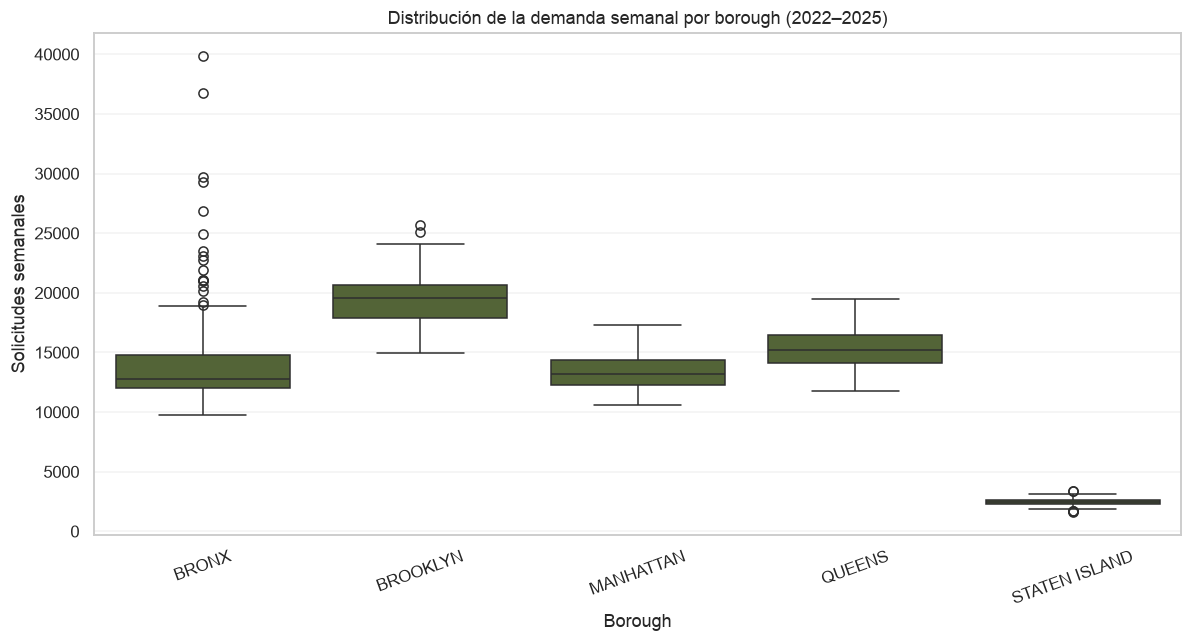

In [33]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=demanda_semanal,
    x="borough",
    y="total_solicitudes",
    color="darkolivegreen"
)

plt.title("Distribución de la demanda semanal por borough (2022–2025)")
plt.xlabel("Borough")
plt.ylabel("Solicitudes semanales")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

Observando los diagramas de caja:
- Bronx: presenta numerosos valores atípicos superiores, algunos cercanos a 40.000 solicitudes semanales. Esto explica su elevada desviación estándar y la diferencia entre su media y mediana.
- Brooklyn: registra la mediana más alta, aproximadamente 19.500 solicitudes semanales. Presenta algunos valores atípicos, pero una distribución más concentrada.
- Manhattan: muestra una demanda relativamente estable, sin valores atípicos visibles.
- Queens: también presenta una distribución bastante concentrada, con valores próximos a 15.000 solicitudes semanales.
- Staten Island: registra una demanda mucho menor en términos absolutos, por lo que su caja aparece comprimida en esta escala.
Es importante recordar que un valor atípico no significa necesariamente un error. Puede representar una semana en la que aumentaron considerablemente las solicitudes.

### 3.3 Histogramas de la demanda semanal

Se examina la forma de la distribución de solicitudes semanales de cada borough para identificar concentración, dispersión y posibles asimetrías.

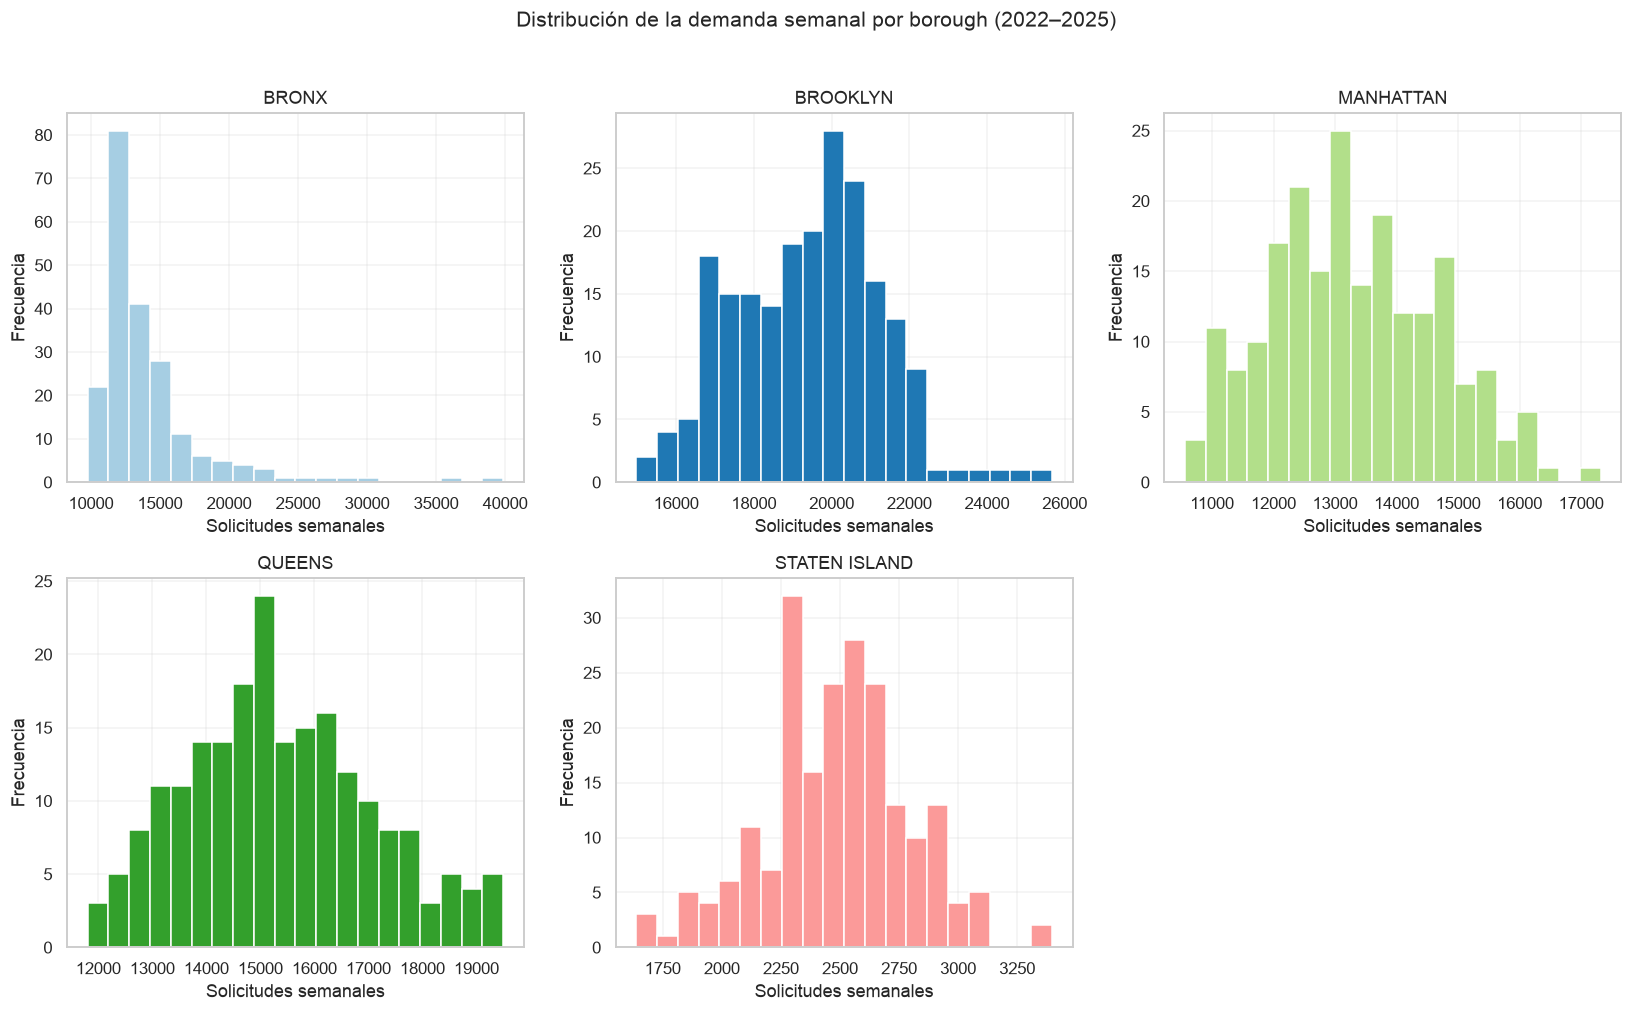

In [34]:
sns.set_style("whitegrid")

boroughs = sorted(demanda_semanal["borough"].unique())

# Crear una paleta y asignar un color a cada borough
colores = dict(zip(boroughs, sns.color_palette("Paired", n_colors=len(boroughs))))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, borough in enumerate(boroughs):
    ax = axes[i]
    
    datos = demanda_semanal.loc[
        demanda_semanal["borough"] == borough,
        "total_solicitudes"
    ]
    
    sns.histplot(
        datos,
        bins=20,
        ax=ax,
        color=colores[borough],
        edgecolor="white",
        alpha=1.0
    )
    
    margen = (datos.max() - datos.min()) * 0.05
    ax.set_xlim(datos.min() - margen, datos.max() + margen)
    
    ax.set_title(borough)
    ax.set_xlabel("Solicitudes semanales")
    ax.set_ylabel("Frecuencia")

# Ocultar el último espacio vacío
axes[-1].axis("off")

fig.suptitle(
    "Distribución de la demanda semanal por borough (2022–2025)",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

Los histogramas evidencian diferencias en la forma y dispersión de la demanda semanal entre boroughs. Bronx presenta una marcada asimetría positiva, caracterizada por semanas con volúmenes excepcionalmente altos de solicitudes. En contraste, Brooklyn, Manhattan, Queens y Staten Island muestran distribuciones más concentradas alrededor de sus valores habituales.

Estas diferencias respaldan la necesidad de considerar el comportamiento histórico de cada borough al establecer los niveles de demanda, evitando utilizar umbrales absolutos iguales para toda la ciudad.

## 4. Construcción de la variable objetivo

Se calcula una referencia histórica de demanda mediante el promedio móvil de las 52 semanas anteriores para cada borough. Esta referencia permitirá evaluar si la demanda de una semana es baja, media o alta en relación con su comportamiento histórico.

In [35]:
demanda_semanal = demanda_semanal.sort_values(
    ["borough", "semana"]
).copy()

demanda_semanal["promedio_52_semanas"] = (
    demanda_semanal
    .groupby("borough")["total_solicitudes"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=52,
            min_periods=52
        ).mean()
    )
)

display(
    demanda_semanal[
        ["borough", "semana", "total_solicitudes", "promedio_52_semanas"]
    ].groupby("borough").head(2)
)

print(
    "Semanas con referencia histórica:",
    demanda_semanal["promedio_52_semanas"].notna().sum()
)

,borough,semana,total_solicitudes,promedio_52_semanas
1,BRONX,2022-01-03,12056,NaN
2,BRONX,2022-01-10,16275,NaN
211,BROOKLYN,2022-01-03,17279,NaN
212,BROOKLYN,2022-01-10,21015,NaN
421,MANHATTAN,2022-01-03,11992,NaN
422,MANHATTAN,2022-01-10,14666,NaN
631,QUEENS,2022-01-03,13271,NaN
632,QUEENS,2022-01-10,14216,NaN
841,STATEN ISLAND,2022-01-03,2634,NaN
842,STATEN ISLAND,2022-01-10,2643,NaN


Semanas con referencia histórica: 780


|Concepto	|Observaciones|
| -------- | -------- |
|Total de observaciones	|1.040|
|Sin referencia histórica |	260|
|Con referencia histórica |	780|

Como el código anterior solo muestra las dos primeras filas de cada borough, todos los valores aparecen como NaN.

Vamos a visualizar las primeras semanas que sí tienen promedio histórico.

In [36]:
# Mostrar las primeras semanas con promedio histórico
demanda_con_historial = demanda_semanal.dropna(
    subset=["promedio_52_semanas"]
).copy()

display(
    demanda_con_historial[
        ["borough", "semana", "total_solicitudes", "promedio_52_semanas"]
    ].groupby("borough").head(3)
)

print("Observaciones con historial:", len(demanda_con_historial))

,borough,semana,total_solicitudes,promedio_52_semanas
53,BRONX,2023-01-02,10994,14090.750000
54,BRONX,2023-01-09,12426,14070.326923
55,BRONX,2023-01-16,11513,13996.307692
263,BROOKLYN,2023-01-02,16572,17770.000000
264,BROOKLYN,2023-01-09,17097,17756.403846
265,BROOKLYN,2023-01-16,16880,17681.057692
473,MANHATTAN,2023-01-02,10956,12313.519231
474,MANHATTAN,2023-01-09,10936,12293.596154
475,MANHATTAN,2023-01-16,10990,12221.865385
683,QUEENS,2023-01-02,12514,13999.038462


Observaciones con historial: 780


Como Brooklyn recibe muchas más solicitudes que Staten Island, no sería adecuado clasificarlos usando los mismos umbrales absolutos.

En cambio, vamos a calcular cuánto representa la demanda de cada semana respecto a su propio promedio histórico.

### 4.1 Demanda relativa respecto al promedio histórico

Se calcula la relación entre la demanda semanal observada y el promedio de las 52 semanas anteriores de cada borough. Esta medida permite comparar variaciones proporcionales, independientemente del volumen habitual de solicitudes.

In [38]:
demanda_con_historial["demanda_relativa"] = (
    demanda_con_historial["total_solicitudes"]
    / demanda_con_historial["promedio_52_semanas"]
)

display(
    demanda_con_historial[
        [
            "borough",
            "semana",
            "total_solicitudes",
            "promedio_52_semanas",
            "demanda_relativa"
        ]
    ].head(10).round({
        "promedio_52_semanas": 3,
        "demanda_relativa": 3
    })
)

print(
    "Observaciones con historial:",
    len(demanda_con_historial)
)

,borough,semana,total_solicitudes,promedio_52_semanas,demanda_relativa
53,BRONX,2023-01-02,10994,14090.750,0.780
54,BRONX,2023-01-09,12426,14070.327,0.883
55,BRONX,2023-01-16,11513,13996.308,0.823
56,BRONX,2023-01-23,12055,13938.712,0.865
57,BRONX,2023-01-30,14801,13883.712,1.066
58,BRONX,2023-02-06,12055,13883.712,0.868
59,BRONX,2023-02-13,11260,13752.846,0.819
60,BRONX,2023-02-20,10842,13692.846,0.792
61,BRONX,2023-02-27,11405,13684.442,0.833
62,BRONX,2023-03-06,11472,13650.942,0.840


Observaciones con historial: 780


In [39]:
estadisticas_relativas = (
    demanda_con_historial
    .groupby("borough")["demanda_relativa"]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .round(3)
)

display(estadisticas_relativas)

,count,mean,std,min,25%,50%,75%,max
borough,,,,,,,,
BRONX,156.0,1.030,0.277,0.742,0.859,0.976,1.097,2.755
BROOKLYN,156.0,1.028,0.080,0.827,0.979,1.023,1.078,1.395
MANHATTAN,156.0,1.024,0.094,0.793,0.957,1.019,1.086,1.281
QUEENS,156.0,1.036,0.096,0.815,0.973,1.026,1.115,1.242
STATEN ISLAND,156.0,1.006,0.130,0.689,0.917,1.011,1.092,1.393


### 4.3 Exploración de umbrales para la variable objetivo

Se examinan los percentiles 33 y 67 de la demanda relativa como posibles límites para clasificar la demanda semanal en tres niveles. Esta exploración permite identificar umbrales candidatos antes de definir la metodología final.

In [40]:
percentiles = (
    demanda_con_historial
    .groupby("borough")["demanda_relativa"]
    .quantile([0.33, 0.67])
    .unstack()
    .rename(columns={
        0.33: "percentil_33",
        0.67: "percentil_67"
    })
    .round(3)
)

display(percentiles)

,percentil_33,percentil_67
borough,,
BRONX,0.906,1.057
BROOKLYN,0.995,1.063
MANHATTAN,0.980,1.062
QUEENS,0.988,1.092
STATEN ISLAND,0.962,1.056


### 4.4 Definición de umbrales para la variable objetivo

Se utilizan los percentiles 33 y 67 de la demanda relativa para proponer tres niveles de demanda: baja, media y alta.

Los umbrales se calculan con los datos de 2023–2024 y se mantienen fijos para clasificar las observaciones de 2025, evitando incorporar información futura en su definición.

In [41]:
# Separación temporal
entrenamiento = demanda_con_historial[
    demanda_con_historial["semana"] < "2025-01-01"
].copy()

evaluacion = demanda_con_historial[
    demanda_con_historial["semana"] >= "2025-01-01"
].copy()

print("Observaciones 2023-2024:", len(entrenamiento))
print("Observaciones 2025:", len(evaluacion))

Observaciones 2023-2024: 525
Observaciones 2025: 255


Ahora calcularemos los percentiles 33 y 67 de la demanda relativa utilizando únicamente los datos de entrenamiento.

In [42]:
# Calcular umbrales con datos de entrenamiento
umbrales = (
    entrenamiento
    .groupby("borough")["demanda_relativa"]
    .quantile([0.33, 0.67])
    .unstack()
    .rename(columns={
        0.33: "umbral_bajo",
        0.67: "umbral_alto"
    })
)

display(umbrales.round(3))

,umbral_bajo,umbral_alto
borough,,
BRONX,0.937,1.069
BROOKLYN,0.992,1.077
MANHATTAN,0.982,1.078
QUEENS,0.988,1.087
STATEN ISLAND,0.919,1.042


### 4.5 Construcción de la variable objetivo `nivel_demanda`

Se clasifica la demanda semanal de cada borough en tres categorías: baja, media y alta, utilizando los percentiles 33 y 67 calculados con los datos de 2023–2024.

Los mismos umbrales se aplican a las observaciones de 2025 para mantener un criterio de clasificación consistente.

In [43]:
# Incorporar los umbrales a cada observación
df_objetivo = demanda_con_historial.merge(
    umbrales,
    on="borough",
    how="left"
)

# Clasificar la demanda semanal
condiciones = [
    df_objetivo["demanda_relativa"] < df_objetivo["umbral_bajo"],
    df_objetivo["demanda_relativa"] > df_objetivo["umbral_alto"]
]

opciones = ["Baja", "Alta"]

df_objetivo["nivel_demanda"] = np.select(
    condiciones,
    opciones,
    default="Media"
)

display(
    df_objetivo[
        [
            "borough",
            "semana",
            "total_solicitudes",
            "demanda_relativa",
            "nivel_demanda"
        ]
    ].head(10)
)

print("Observaciones clasificadas:", len(df_objetivo))

,borough,semana,total_solicitudes,demanda_relativa,nivel_demanda
0,BRONX,2023-01-02,10994,0.780228,Baja
1,BRONX,2023-01-09,12426,0.883135,Baja
2,BRONX,2023-01-16,11513,0.822574,Baja
3,BRONX,2023-01-23,12055,0.864858,Baja
4,BRONX,2023-01-30,14801,1.066069,Media
5,BRONX,2023-02-06,12055,0.868284,Baja
6,BRONX,2023-02-13,11260,0.818740,Baja
7,BRONX,2023-02-20,10842,0.791800,Baja
8,BRONX,2023-02-27,11405,0.833428,Baja
9,BRONX,2023-03-06,11472,0.840382,Baja


Observaciones clasificadas: 780


### 4.6 Distribución y desbalance de la variable objetivo

Se analiza la frecuencia absoluta y porcentual de las categorías Baja, Media y Alta para identificar posibles desbalances en la variable objetivo.

In [44]:
# Distribución de la variable objetivo
orden = ["Baja", "Media", "Alta"]

distribucion = (
    df_objetivo["nivel_demanda"]
    .value_counts()
    .reindex(orden, fill_value=0)
)

porcentajes = (
    df_objetivo["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden, fill_value=0)
    .mul(100)
)

resumen_clases = pd.DataFrame({
    "Frecuencia": distribucion,
    "Porcentaje (%)": porcentajes.round(2)
})

display(resumen_clases)

,Frecuencia,Porcentaje (%)
nivel_demanda,,
Baja,262,33.59
Media,273,35.00
Alta,245,31.41


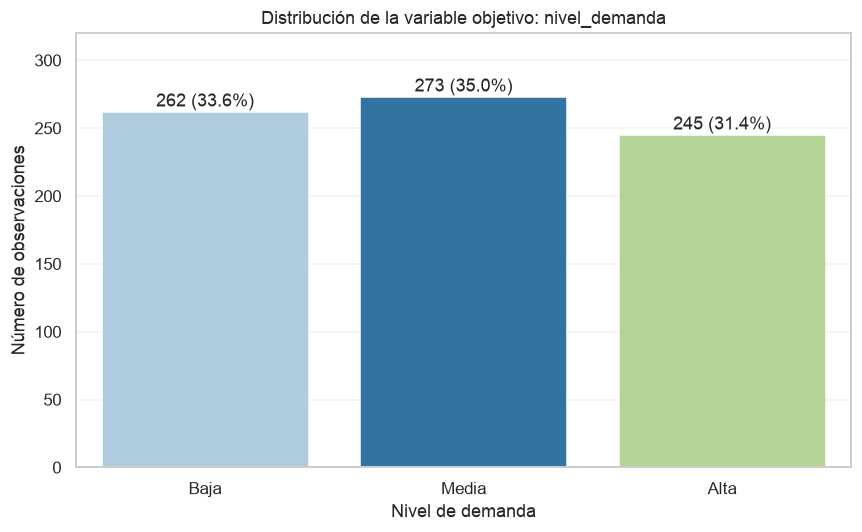

In [45]:
colores = sns.color_palette("Paired", 3)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=resumen_clases.index,
    y=resumen_clases["Frecuencia"],
    hue=resumen_clases.index,
    palette=colores,
    legend=False
)

for i, (_, fila) in enumerate(resumen_clases.iterrows()):
    ax.text(
        i,
        fila["Frecuencia"] + 4,
        f'{int(fila["Frecuencia"])} ({fila["Porcentaje (%)"]:.1f}%)',
        ha="center"
    )

plt.title("Distribución de la variable objetivo: nivel_demanda")
plt.xlabel("Nivel de demanda")
plt.ylabel("Número de observaciones")
plt.ylim(0, 320)
plt.tight_layout()
plt.show()

La variable objetivo nivel_demanda presenta una distribución global relativamente equilibrada. La categoría Media concentra el 35,00 % de las observaciones, seguida de Baja con el 33,59 % y Alta con el 31,41 %.

La diferencia entre las clases más y menos frecuentes es de 3,59 puntos porcentuales, por lo que no se identifica un desbalance global significativo.

Este resultado debe interpretarse considerando que los umbrales de clasificación se construyeron mediante percentiles 33 y 67, una metodología que favorece distribuciones equilibradas en los datos utilizados para calcularlos. Por tanto, el equilibrio observado no implica necesariamente que los episodios de demanda operativamente alta sean igual de frecuentes que los de demanda media o baja.

### 4.7 Distribución de la variable objetivo por borough

Se analiza la proporción de los niveles de demanda Baja, Media y Alta en cada borough, con el fin de identificar posibles diferencias en el balance de las clases.

In [46]:
# Distribución porcentual de las clases por borough
orden = ["Baja", "Media", "Alta"]

balance_borough = pd.crosstab(
    df_objetivo["borough"],
    df_objetivo["nivel_demanda"],
    normalize="index"
).reindex(columns=orden, fill_value=0) * 100

display(balance_borough.round(2))

nivel_demanda,Baja,Media,Alta
borough,,,
BRONX,42.31,26.92,30.77
BROOKLYN,32.05,42.31,25.64
MANHATTAN,34.62,37.18,28.21
QUEENS,33.33,32.69,33.97
STATEN ISLAND,25.64,35.90,38.46


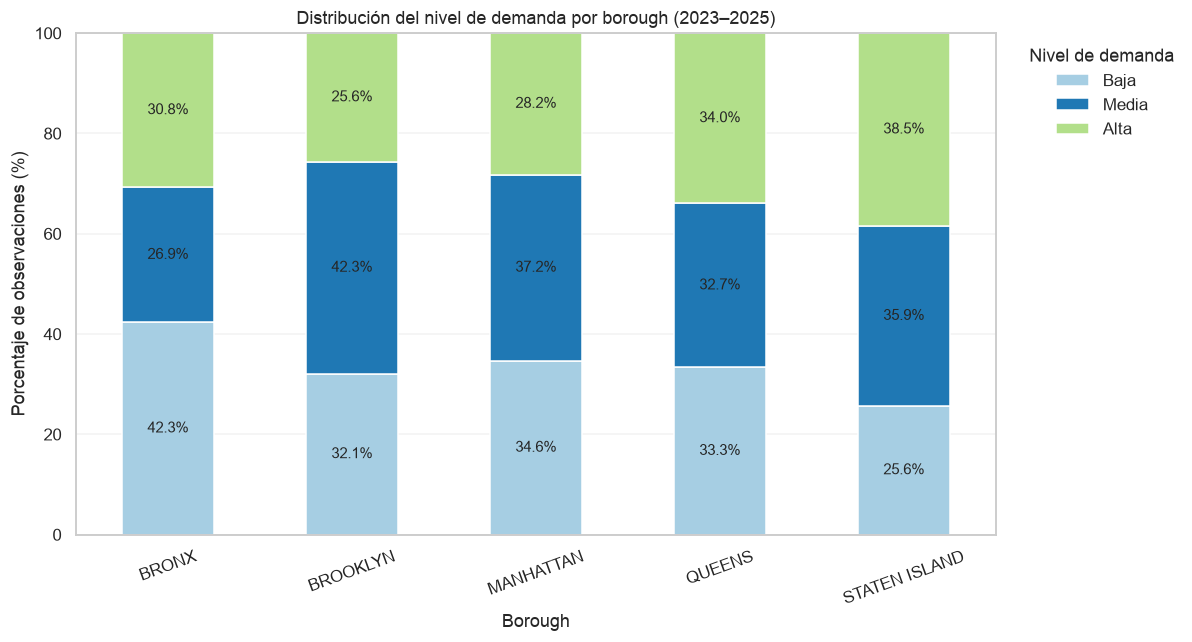

In [48]:
# Colores de la paleta Paired
colores = sns.color_palette("Paired", 3)

ax = balance_borough[["Baja", "Media", "Alta"]].plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=colores,
    edgecolor="white"
)

# Mostrar porcentajes dentro de cada segmento
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f%%",
        label_type="center",
        fontsize=10
    )

plt.title("Distribución del nivel de demanda por borough (2023–2025)")
plt.xlabel("Borough")
plt.ylabel("Porcentaje de observaciones (%)")
plt.xticks(rotation=20)
plt.legend(
    title="Nivel de demanda",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Aunque la variable objetivo presenta una distribución global relativamente equilibrada, se observan diferencias entre boroughs. Bronx registra la mayor proporción de semanas con demanda baja (42,31 %), mientras que Brooklyn presenta una mayor concentración de demanda media (42,31 %). Queens muestra la distribución más equilibrada entre las tres categorías.

Por su parte, Staten Island registra la mayor proporción de semanas clasificadas como demanda alta (38,46 %). Esta clasificación es relativa al comportamiento histórico de cada borough y no implica que Staten Island tenga un mayor volumen absoluto de solicitudes.

Estos resultados evidencian la importancia de evaluar el balance de las clases tanto a nivel global como por borough.

### 4.8 Distribución de la variable objetivo por período

Se compara la distribución de las clases Baja, Media y Alta entre el período utilizado para definir los umbrales (2023–2024) y el año 2025, con el propósito de identificar posibles cambios en el balance de las categorías.

In [51]:
# Identificar los períodos
df_objetivo["periodo"] = np.where(
    df_objetivo["semana"] < "2025-01-01",
    "2023-2024",
    "2025"
)

# Calcular la distribución porcentual por período
balance_periodo = pd.crosstab(
    df_objetivo["periodo"],
    df_objetivo["nivel_demanda"],
    normalize="index"
).reindex(
    columns=["Baja", "Media", "Alta"],
    fill_value=0
) * 100

display(balance_periodo.round(2))

nivel_demanda,Baja,Media,Alta
periodo,,,
2023-2024,33.33,33.33,33.33
2025,34.12,38.43,27.45


La distribución de la variable objetivo presenta diferencias entre los períodos analizados. En 2023–2024, las categorías Baja, Media y Alta representan cada una el 33,33 % de las observaciones, como resultado de utilizar los percentiles 33 y 67 para establecer los umbrales de clasificación.

En 2025, utilizando los mismos umbrales, la categoría Media aumenta al 38,43 %, mientras que Alta disminuye al 27,45 % y Baja representa el 34,12 %. Esto evidencia un cambio moderado en la distribución de las clases respecto al período de referencia.

Aunque no se observa un desbalance extremo, estos cambios deberán considerarse en las etapas posteriores de entrenamiento y evaluación del modelo.

### 4.9 Distribución anual de la variable objetivo por borough

Se analiza cómo se distribuyen las categorías Baja, Media y Alta en cada borough durante 2023, 2024 y 2025, con el fin de identificar cambios temporales en la composición de la demanda semanal.

In [52]:
# Crear columna de año
df_objetivo["anio"] = df_objetivo["semana"].dt.year

# Quedarnos con 2023, 2024 y 2025
df_anual = df_objetivo[df_objetivo["anio"].isin([2023, 2024, 2025])].copy()

# Tabla de porcentajes por borough, año y nivel_demanda
tabla_anual = (
    pd.crosstab(
        [df_anual["borough"], df_anual["anio"]],
        df_anual["nivel_demanda"],
        normalize="index"
    )
    .reindex(columns=["Baja", "Media", "Alta"], fill_value=0)
    * 100
)

display(tabla_anual.round(2))

nivel_demanda        Baja  Media   Alta
borough       anio                     
BRONX         2023  53.85  32.69  13.46
              2024  13.21  33.96  52.83
              2025  60.78  13.73  25.49
BROOKLYN      2023  23.08  30.77  46.15
              2024  43.40  35.85  20.75
              2025  29.41  60.78   9.80
MANHATTAN     2023  28.85  32.69  38.46
              2024  37.74  33.96  28.30
              2025  37.25  45.10  17.65
QUEENS        2023  28.85  25.00  46.15
              2024  37.74  41.51  20.75
              2025  33.33  31.37  35.29
STATEN ISLAND 2023  32.69  34.62  32.69
              2024  33.96  32.08  33.96
              2025   9.80  41.18  49.02

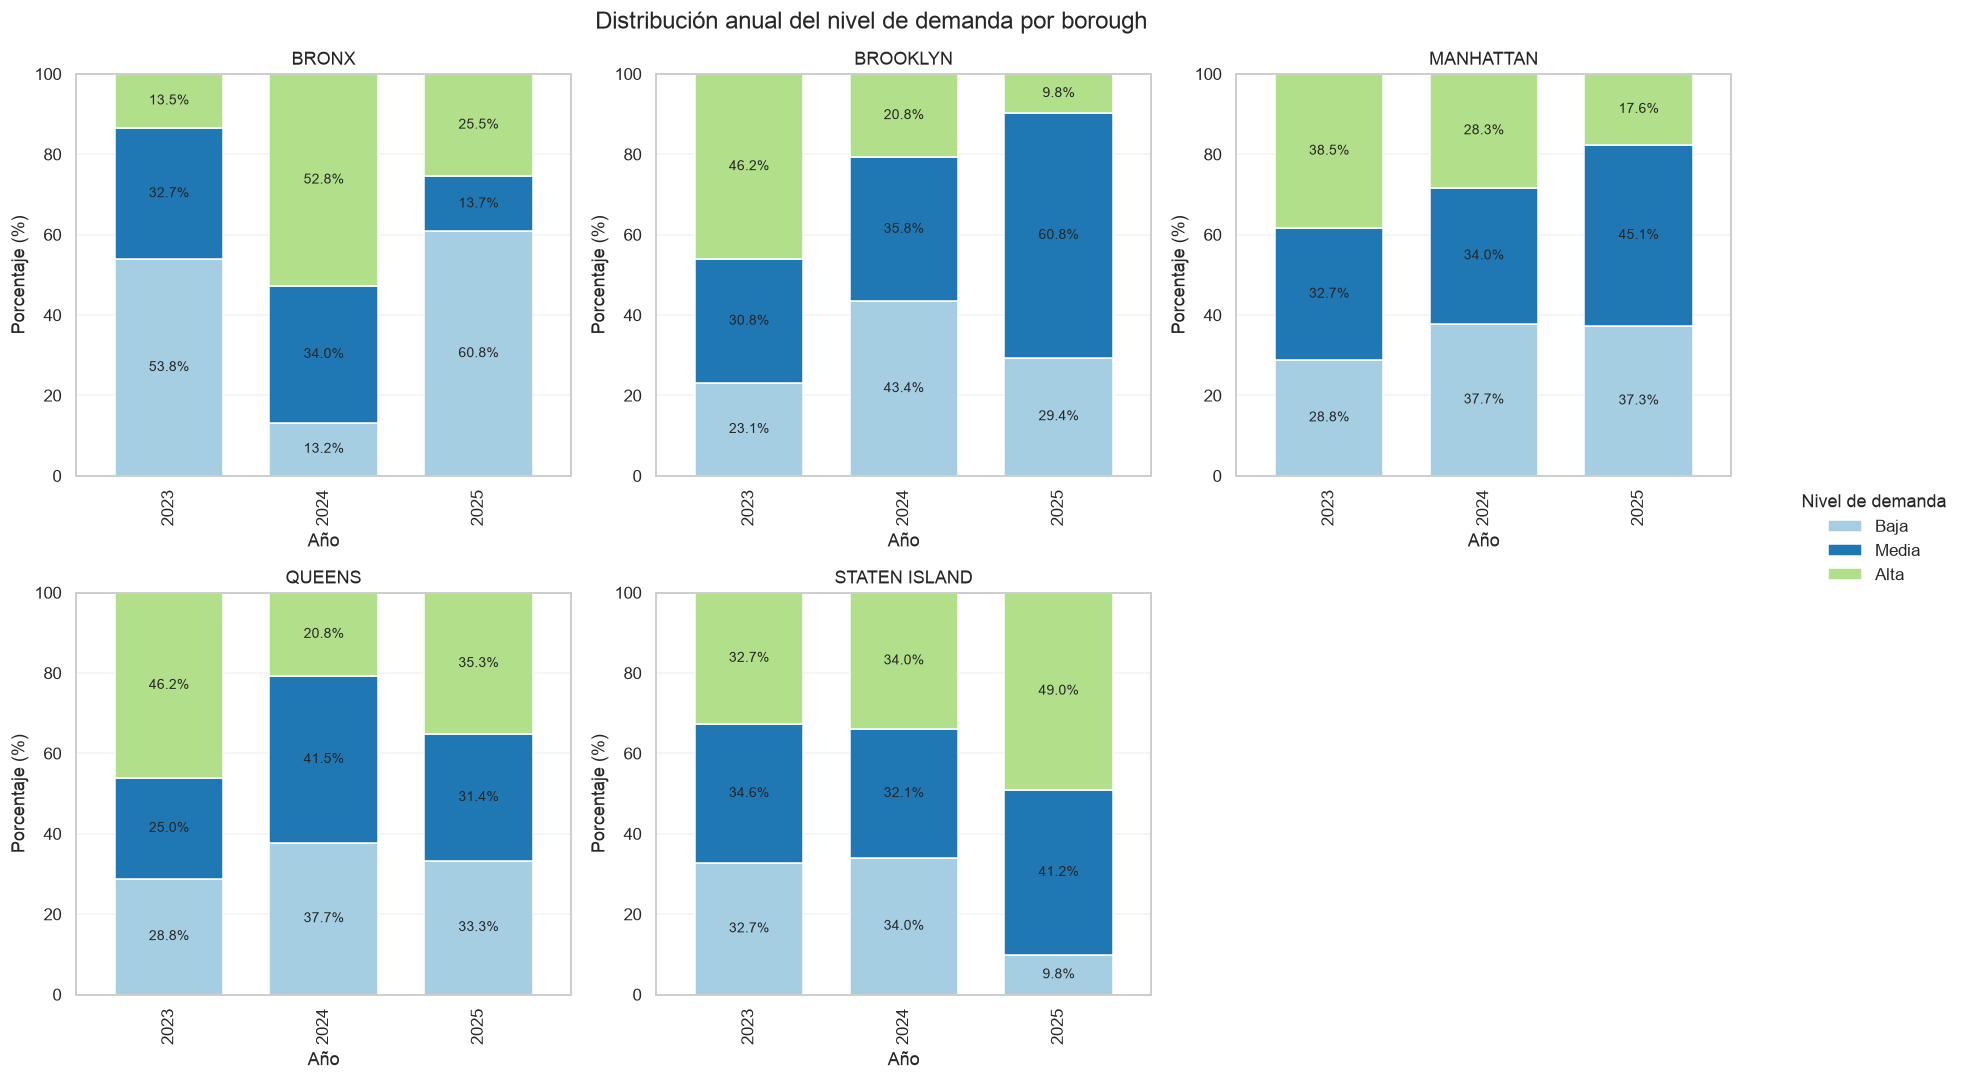

In [53]:
colores = sns.color_palette("Paired", 3)
boroughs = sorted(df_anual["borough"].unique())

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, borough in enumerate(boroughs):
    ax = axes[i]
    
    datos_plot = tabla_anual.loc[borough]
    
    datos_plot.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=colores,
        edgecolor="white",
        width=0.7
    )
    
    # Etiquetas dentro de las barras
    for contenedor in ax.containers:
        etiquetas = []
        for barra in contenedor:
            h = barra.get_height()
            etiquetas.append(f"{h:.1f}%" if h > 5 else "")
        ax.bar_label(contenedor, labels=etiquetas, label_type="center", fontsize=9)
    
    ax.set_title(borough)
    ax.set_xlabel("Año")
    ax.set_ylabel("Porcentaje (%)")
    ax.set_ylim(0, 100)
    ax.legend_.remove()

# Ocultar el último subplot vacío
axes[-1].axis("off")

# Leyenda general afuera
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    title="Nivel de demanda",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

fig.suptitle("Distribución anual del nivel de demanda por borough", fontsize=16)
plt.tight_layout()
plt.show()

La distribución anual de la variable objetivo evidencia cambios importantes en la frecuencia de los niveles de demanda entre boroughs.

Bronx presenta una variación destacada: la proporción de semanas con demanda alta aumenta del 13,5 % en 2023 al 52,8 % en 2024, mientras que en 2025 predomina la categoría Baja (60,8 %). Brooklyn y Manhattan muestran una disminución de la proporción de semanas clasificadas como Alta hacia 2025.

En contraste, Staten Island registra un incremento de la categoría Alta, que alcanza el 49,0 % en 2025. Queens presenta variaciones más moderadas, con un descenso de la categoría Alta en 2024 y una recuperación en 2025.

Estos resultados muestran que, aunque la variable objetivo se encuentra relativamente equilibrada a nivel global, su distribución cambia entre años y boroughs. Esto refuerza la importancia de considerar la evolución temporal de la demanda al evaluar futuros modelos predictivos.

Nota: Los porcentajes representan proporciones de semanas clasificadas según los umbrales históricos, no proporciones del total de solicitudes.

## 5. Conclusiones

El análisis univariado de las solicitudes NYC 311 permitió caracterizar la demanda semanal de los cinco boroughs de Nueva York durante el período 2022–2025 y explorar la construcción de una variable objetivo categórica.

**Principales hallazgos:**

1. **Diferencias en la demanda semanal:** Brooklyn presenta el mayor volumen promedio de solicitudes semanales, mientras que Staten Island registra el menor. Esto confirma que los boroughs operan en escalas de demanda diferentes.

2. **Variabilidad y valores extremos:** Bronx presenta la mayor dispersión y una distribución marcadamente asimétrica hacia valores altos. En contraste, los demás boroughs muestran comportamientos semanales relativamente más estables.

3. **Referencia histórica:** Se calculó el promedio de las 52 semanas anteriores por borough para obtener una medida de demanda relativa. Las primeras 52 semanas de cada borough se utilizaron como historial, dejando 780 observaciones disponibles para el análisis de la variable objetivo.

4. **Construcción de la variable objetivo:** Se propuso clasificar `nivel_demanda` en Baja, Media y Alta mediante los percentiles 33 y 67 de la demanda relativa, calculados exclusivamente con las observaciones de 2023–2024.

5. **Balance de clases:** La variable objetivo presenta una distribución global relativamente equilibrada: Baja (33,59 %), Media (35,00 %) y Alta (31,41 %). Sin embargo, se identifican diferencias entre boroughs y un cambio moderado en las proporciones durante 2025.

**Conclusión general:** Los resultados respaldan la utilización de referencias históricas específicas por borough para caracterizar la demanda semanal. La variable `nivel_demanda` constituye una propuesta inicial de clasificación que podrá utilizarse en las etapas posteriores del proyecto, una vez que el equipo valide los umbrales y su interpretación operativa.